# Lecture 1 · Practical 2 — Who leaves at which price, and which premium does Arvena need?
### Classification with neural networks, and a finished pricing decision

**Version: instructor solution**

### Where this notebook sits in Lecture 1
> **The decision.** Arvena must file its basic-insurance premiums for 2027. The premium must cover the expected cost of the customers it will insure; a lower premium keeps more customers.

| notebook | question | status |
|---|---|---|
| P1 | How much will each customer cost in 2027? | done → `outputs/cost_forecast_2027.parquet` |
| **P2 (this one)** | Which households leave at a given price? Which premium covers the cost of those who stay? | **classification, then the decision** |
| P3 | Where do neural networks clearly beat other models? | sequences of activity data |

**Run Practical 1 first**: this notebook reads its forecast file.

### Learning goals
1. Build a renewal panel and evaluate classifiers for a **rare event** (about 6% of households switch).
2. Compare logistic regression, gradient boosting and neural networks, and explain why they perform alike here.
3. See why an unconstrained network can give **economically wrong answers** to "what if we raise the price?", and fix it by architecture.
4. **Combine** the cost forecast (P1) and the switching model into one decision: the smallest premium that covers the cost of the customers who stay — and see why ignoring *who* leaves gives the wrong answer.

Runtime: about 2 minutes on a laptop CPU.

## 0 · The renewal in plain words
Every autumn, each insurer announces next year's premium. Households have until 30 November to move to another insurer for 1 January. Basic-insurance benefits are identical by law, so households compare **prices**. Each year roughly 5–9% of insured people switch.

Three forces drive the decision:
* **saving:** how much cheaper the cheapest insurer is for the same cover;
* **increase:** how much one's own premium rises, especially if it rises more than the market;
* **ties and inertia:** older people, chronically ill people and people with a supplementary hospital contract at the same insurer rarely move (a new supplementary contract would require a health questionnaire).

In [1]:
import time, numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, torch.nn as nn
from pathlib import Path
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, average_precision_score, log_loss, brier_score_loss
import course_utils as cu

SEED = 2026
np.random.seed(SEED); torch.manual_seed(SEED); torch.set_num_threads(2)
pd.set_option("display.precision", 3); pd.set_option("display.width", 140)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
assert Path("outputs/cost_forecast_2027.parquet").exists(), "Run Practical 1 first: it writes outputs/cost_forecast_2027.parquet"

# Part A · Predicting who switches

## 1 · The renewal panel
Households decide together (fewer than 1% split between insurers), so we model **one row per household and renewal**. `cu.build_switching_panel()` (read it in `course_utils.py`):
1. takes every person insured in year $t$ with their current cover;
2. prices **the same cover** for $t+1$ at **all eight insurers** from the published tariff tables — what a household sees on a comparison website;
3. sums over household members and derives the price signals;
4. labels `switched = 1` if the household's insurer changes on 1 January of $t+1$.

It returns the renewals 1 January 2015 – 2026 (history, labels known) and the **live renewal of 1 January 2027**, which we never use for training.

| feature | definition |
|---|---|
| `savings` | $1 - $ cheapest premium / own premium, for the same cover |
| `own_increase` | own premium $t+1$ / own premium $t$ − 1 |
| `mkt_increase` | average `own_increase` in the canton that year |
| `excess_increase` | $\max(\text{own} - \text{market}, 0)$: being singled out |
| ties and profile | `hosp_tie` (hospital supplement at the same insurer), `any_vvg_tie`, `chronic`, `age_head`, `n_members`, `income_band`, … |

In [2]:
t0 = time.time()
H, L = cu.build_switching_panel()
for d in (H, L):
    d["excess_increase"] = np.maximum(d.own_increase - d.mkt_increase, 0)
print(f"built in {time.time() - t0:.0f} s · history: {len(H):,} household-renewals · live 2027: {len(L):,} households")
H[["household_id", "year", "okp_insurer", "n_members", "age_head", "own_now", "own_next", "own_increase", "savings", "hosp_tie", "switched"]].head()

built in 24 s · history: 35,772 household-renewals · live 2027: 2,973 households


,household_id,year,okp_insurer,n_members,age_head,own_now,own_next,own_increase,savings,hosp_tie,switched
0,1,2014,SOR,1,69,5275.56,5547.00,0.051,0.064,1,0
1,1,2015,SOR,1,70,5547.00,5710.80,0.030,0.089,0,1
2,2,2014,SOR,3,27,6603.84,7086.24,0.073,0.081,0,0
3,2,2015,SOR,3,28,7424.04,9385.56,0.264,0.121,0,0
4,2,2016,SOR,3,29,9385.56,9915.36,0.056,0.109,0,1


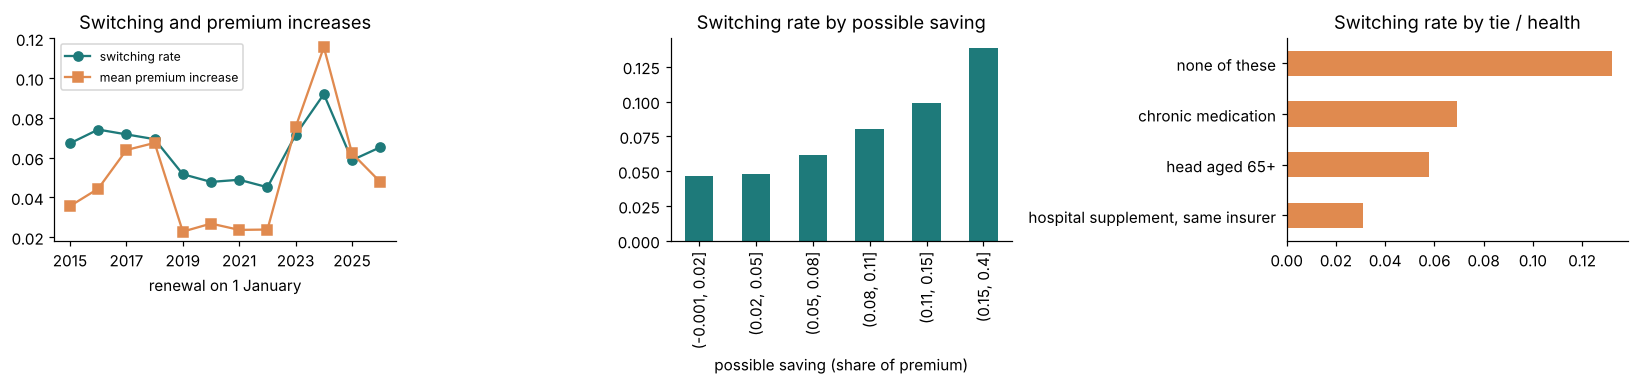

switching rate: history 6.4% · live 2027 5.6%
last year's cost per member (CHF): {'stayed': 5088.0, 'switched': 2969.0}


In [3]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
H.groupby(H.year + 1).switched.mean().plot(ax=ax[0], marker="o", color="#1E7A7A", label="switching rate")
H.groupby(H.year + 1).mkt_increase.mean().plot(ax=ax[0], marker="s", color="#E08A4F", label="mean premium increase")
ax[0].set(title="Switching and premium increases", xlabel="renewal on 1 January"); ax[0].set_xticks(range(2015, 2027, 2)); ax[0].legend(fontsize=8)
H.groupby(pd.cut(H.savings, [-.001, .02, .05, .08, .11, .15, .4]), observed=True).switched.mean().plot.bar(ax=ax[1], color="#1E7A7A", title="Switching rate by possible saving")
ax[1].set_xlabel("possible saving (share of premium)")
grp = H.assign(group=np.select([H.hosp_tie == 1, H.chronic == 1, H.age_head >= 65], ["hospital supplement, same insurer", "chronic medication", "head aged 65+"], "none of these"))
grp.groupby("group").switched.mean().sort_values().plot.barh(ax=ax[2], color="#E08A4F", title="Switching rate by tie / health"); ax[2].set_ylabel("")
plt.tight_layout(); plt.show()
H["cost_per_member"] = H.hh_cost_t / H.n_members
print(f"switching rate: history {H.switched.mean():.1%} · live 2027 {L.switched.mean():.1%}")
print("last year's cost per member (CHF):", H.groupby("switched").cost_per_member.mean().round(0).rename({0: "stayed", 1: "switched"}).to_dict())

Switching rises with premium increases and with the possible saving, and households with ties switch far less. The last line prints a fact that will matter in Part B: **households that switch cost much less per member than those that stay**. When an insurer raises its price, it loses mostly cheap customers — *adverse selection* for the insurer that raises its price.

## 2 · Evaluation design for a rare event
| set | renewals | use |
|---|---|---|
| train | 1 January 2015–2024 | fit |
| validation | 2025–2026 | early stopping |
| test | **2027 (live)** | final scores |

With 6% positives, "nobody switches" is 94% accurate, so accuracy is useless. We report **ROC-AUC** (ranking), **average precision** (AP; a random model scores the base rate ≈ 0.06), **log-loss** and the **mean predicted probability** next to the observed rate — the decision in Part B multiplies probabilities by francs, so their level matters.

In [4]:
PRICE = ["savings", "excess_increase", "mkt_increase"]
CTRL_NUM = ["age_head", "n_members", "hosp_tie", "any_vvg_tie", "chronic", "income_band", "mean_deductible", "log_hh_cost_t"]
CTRL_CAT = ["language", "okp_insurer", "municipality_type"]
tr, va, te = H[H.year <= 2023], H[H.year >= 2024], L
scores = []
def evaluate(name, p, d=te):
    r = dict(model=name, AUC=roc_auc_score(d.switched, p), AP=average_precision_score(d.switched, p), logloss=log_loss(d.switched, p),
             mean_pred=p.mean(), observed=d.switched.mean())
    scores.append(r); print(f"{name:30s} AUC {r['AUC']:.3f}  AP {r['AP']:.3f}  log-loss {r['logloss']:.4f}  mean p {r['mean_pred']:.3f} (observed {r['observed']:.3f})")

## 3 · Four models
* **Logistic regression**: log-odds linear in the features; coefficients are odds ratios.
* **Gradient boosting**: trees, the strongest non-network model on tables.
* **MLP**: two hidden layers; output = logit $z$, probability $\sigma(z)$, loss = binary cross-entropy $-[y\log\sigma(z)+(1-y)\log(1-\sigma(z))]$, which is the log-loss metric itself.
* **Structured network** (Section 4): a network whose price response is guaranteed to have the right sign.

In [5]:
pre = ColumnTransformer([("num", StandardScaler(), PRICE + CTRL_NUM), ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CTRL_CAT)]).fit(tr)
logit = LogisticRegression(max_iter=5000).fit(pre.transform(tr), tr.switched)
evaluate("logistic regression", logit.predict_proba(pre.transform(te))[:, 1])
gbm = HistGradientBoostingClassifier(learning_rate=0.05, max_iter=400, min_samples_leaf=100, early_stopping=True, random_state=SEED).fit(pre.transform(tr), tr.switched)
evaluate("gradient boosting", gbm.predict_proba(pre.transform(te))[:, 1])

ctrl = ColumnTransformer([("num", StandardScaler(), CTRL_NUM), ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CTRL_CAT)]).fit(tr)
PRICE_SCALE = 10.0     # shares (0.05 = 5%) times 10: a scale comparable to the standardised controls
def tensors(d):
    return (torch.tensor(ctrl.transform(d), dtype=torch.float32), torch.tensor(d[PRICE].values * PRICE_SCALE, dtype=torch.float32),
            torch.tensor(d.switched.values, dtype=torch.float32))
T_tr, T_va, T_te = tensors(tr), tensors(va), tensors(te)
n_ctrl = T_tr[0].shape[1]

class PlainMLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.f = nn.Sequential(nn.Linear(n_ctrl + len(PRICE), 32), nn.ReLU(), nn.Dropout(0.1), nn.Linear(32, 16), nn.ReLU(), nn.Linear(16, 1))
    def forward(self, x, r): return self.f(torch.cat([x, r], 1)).squeeze(1)

def train(model, epochs=30, lr=2e-3, batch=256, T_tr=T_tr, T_va=T_va):
    torch.manual_seed(SEED); opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    bce = nn.BCEWithLogitsLoss(); best = (np.inf, None)
    for ep in range(epochs):
        model.train(); perm = torch.randperm(len(T_tr[2]))
        for i in range(0, len(perm), batch):
            j = perm[i:i + batch]; opt.zero_grad(); bce(model(T_tr[0][j], T_tr[1][j]), T_tr[2][j]).backward(); opt.step()
        model.eval()
        with torch.no_grad(): lv = bce(model(T_va[0], T_va[1]), T_va[2]).item()
        if lv < best[0]: best = (lv, {k: v.clone() for k, v in model.state_dict().items()})
    model.load_state_dict(best[1]); return model

def proba(model, T, price_multiplier=1.0):
    model.eval()
    with torch.no_grad(): return torch.sigmoid(model(T[0], T[1] * price_multiplier)).numpy()

mlp = train(PlainMLP())
evaluate("MLP", proba(mlp, T_te))

logistic regression            AUC 0.724  AP 0.139  log-loss 0.1997  mean p 0.059 (observed 0.056)


gradient boosting              AUC 0.706  AP 0.131  log-loss 0.2034  mean p 0.060 (observed 0.056)


MLP                            AUC 0.711  AP 0.134  log-loss 0.2034  mean p 0.069 (observed 0.056)


**All three rank households about equally well** (AUC ≈ 0.71–0.72). This is the expected result when the true decision process is close to linear in the log-odds, as household switching is: extra flexibility buys nothing and adds variance. If a network is not more *accurate* here, is it useless? The next section shows where it still matters.

## 4 · The question pricing really asks: "what if we raise the price?"
A pricing team uses the model **counterfactually**: it changes the price inputs and reads off the new switching probabilities. Economics requires that a larger possible saving, a larger own increase or a larger market increase never makes a household *less* likely to leave. A flexible model does not know this rule. We test it with a **price sweep**: hold everything else fixed, set one price signal to each value of a grid, and check whether any probability goes down as the signal goes up.

### ✏️ Exercise 1 — measure wrong-sign price responses
Write `violation_share(model, T, col, grid)` returning the share of households whose probability **decreases** (by more than $10^{-4}$) somewhere along `grid` when price signal `col` is set to each grid value (remember `PRICE_SCALE`).

In [6]:
# ✅ SOLUTION
def violation_share(model, T, col, grid, tol=1e-4):
    model.eval(); P = []
    with torch.no_grad():
        for v in grid:
            r = T[1].clone(); r[:, col] = v * PRICE_SCALE
            P.append(torch.sigmoid(model(T[0], r)).numpy())
    return float((np.diff(np.stack(P, 1), axis=1) < -tol).any(axis=1).mean())

In [7]:
GRIDS = {"savings": np.linspace(0, .35, 15), "excess_increase": np.linspace(0, .30, 13), "mkt_increase": np.linspace(-.01, .17, 10)}
def monotonicity(model): return {k: f"{violation_share(model, T_te, i, g):.1%}" for i, (k, g) in enumerate(GRIDS.items())}
print("MLP on 29,839 rows — households with a wrong-sign response:", monotonicity(mlp))
small = []
for s in range(3):
    idx = torch.randperm(len(T_tr[2]), generator=torch.Generator().manual_seed(s))[:1500]
    m_s = train(PlainMLP(), epochs=60, T_tr=tuple(t[idx] for t in T_tr))
    small.append({"training sample": s, **monotonicity(m_s)})
print("\nthe same MLP trained on 1,500 rows (a small insurer, a new product):")
pd.DataFrame(small).set_index("training sample")

MLP on 29,839 rows — households with a wrong-sign response: {'savings': '0.0%', 'excess_increase': '0.0%', 'mkt_increase': '0.1%'}



the same MLP trained on 1,500 rows (a small insurer, a new product):


,savings,excess_increase,mkt_increase
training sample,,,
0,86.3%,0.0%,99.9%
1,0.0%,0.0%,93.7%
2,0.1%,0.0%,11.9%


On the full data the network happens to respond correctly. Trained on 1,500 rows, it often predicts that households become *less* likely to leave when the market rises or when they could save more. Used for pricing, such a model would recommend raising prices exactly where it is most dangerous. The correct behaviour on large data was an accident of plenty of data, not a property of the model.

### 4.1 · A structured network: flexible where we know little, constrained where theory is clear
$$ z(\mathbf{x}, \mathbf{r}) = a(\mathbf{x}) + \sum_k b_k(\mathbf{x})\, r_k, \qquad b_k(\mathbf{x}) = \operatorname{softplus}(g_k(\mathbf{x})) = \log\!\big(1+e^{g_k(\mathbf{x})}\big) \ge 0 .$$
* $a(\mathbf{x})$, a small network, captures who tends to switch regardless of price;
* $g(\mathbf{x})$, another small network, outputs one number per price signal; softplus turns it into a **positive slope**;
* price signals $\mathbf{r}$ enter linearly with household-specific positive slopes.

By construction, every household's probability rises with every price signal, and the slope $b_k(\mathbf{x})$ is readable as that household's **price sensitivity**. This follows discrete-choice economics (Train, 2009) and the literature on monotone networks (Sill, 1998).

### ✏️ Exercise 2 — the forward pass
Return $a(\mathbf{x}) + \sum_k \operatorname{softplus}(g_k(\mathbf{x}))\,r_k$ as a 1-D tensor.

In [8]:
# ✅ SOLUTION
class StructuredChoiceNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.a = nn.Sequential(nn.Linear(n_ctrl, 32), nn.ReLU(), nn.Dropout(0.1), nn.Linear(32, 1))
        self.g = nn.Sequential(nn.Linear(n_ctrl, 16), nn.ReLU(), nn.Linear(16, len(PRICE)))
    def slopes(self, x): return nn.functional.softplus(self.g(x))
    def forward(self, x, r): return self.a(x).squeeze(1) + (self.slopes(x) * r).sum(1)

structured network             AUC 0.713  AP 0.137  log-loss 0.2024  mean p 0.067 (observed 0.056)


structured network, wrong-sign responses — all data: {'savings': '0.0%', 'excess_increase': '0.0%', 'mkt_increase': '0.0%'} · 1,500 rows: {'savings': '0.0%', 'excess_increase': '0.0%', 'mkt_increase': '0.0%'}


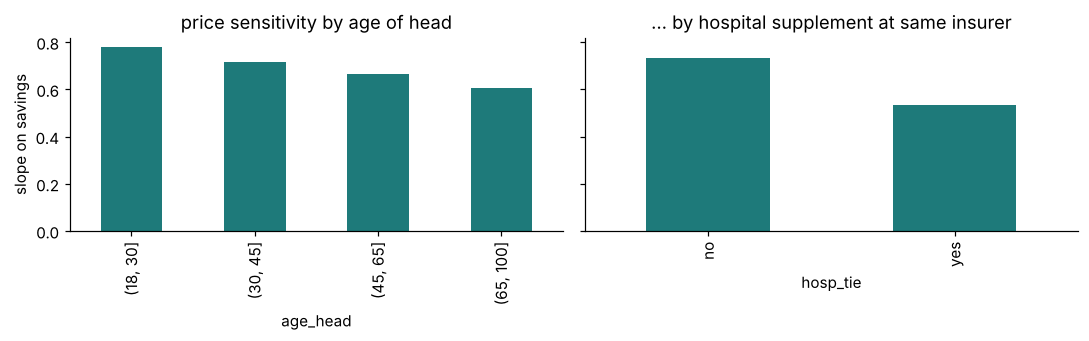

,AUC,AP,logloss,mean_pred,observed
model,,,,,
logistic regression,0.724,0.139,0.200,0.059,0.056
gradient boosting,0.706,0.131,0.203,0.060,0.056
MLP,0.711,0.134,0.203,0.069,0.056
structured network,0.713,0.137,0.202,0.067,0.056


In [9]:
snet = train(StructuredChoiceNet())
evaluate("structured network", proba(snet, T_te))
idx = torch.randperm(len(T_tr[2]), generator=torch.Generator().manual_seed(0))[:1500]
s_small = train(StructuredChoiceNet(), epochs=60, T_tr=tuple(t[idx] for t in T_tr))
print("structured network, wrong-sign responses — all data:", monotonicity(snet), "· 1,500 rows:", monotonicity(s_small))
with torch.no_grad(): b = snet.slopes(T_te[0])[:, 0].numpy()
g = te.assign(slope=b)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2), sharey=True)
g.groupby(pd.cut(g.age_head, [18, 30, 45, 65, 100]), observed=True).slope.mean().plot.bar(ax=ax[0], color="#1E7A7A", title="price sensitivity by age of head")
g.groupby("hosp_tie").slope.mean().rename({0: "no", 1: "yes"}).plot.bar(ax=ax[1], color="#1E7A7A", title="… by hospital supplement at same insurer")
ax[0].set_ylabel("slope on savings"); plt.tight_layout(); plt.show()
pd.DataFrame(scores).set_index("model").style.format("{:.3f}")

The structured network ranks as well as the others, never gives a wrong-sign answer, and tells us *who* is price-sensitive: young households and households without a hospital supplement at the same insurer. The two networks over-predict the 2027 switching rate somewhat (6.7–6.9% predicted against 5.6% observed; the validation renewals had a higher rate than 2027). The decision below therefore errs on the side of caution: it assumes slightly more households leave than will.

---
# Part B · The decision: Arvena's 2027 premium

## 5 · Setting up the decision
### 5.1 · The ingredients
For each of Arvena's households $h$ (live renewal 2027):

| symbol | meaning | source |
|---|---|---|
| $P_h$ | annual premium of the household under Arvena's **draft 2027 tariff** | tariff tables |
| $C_h$ | expected claims Arvena pays for the household in 2027 | **Practical 1** forecast |
| $p_h(m)$ | probability that the household leaves if Arvena multiplies its draft tariff by $m$ | structured network |
| $R$ | Arvena's payment into the federal **risk-equalisation** fund per insured person | 2026 accounts |
| 5% | administrative costs, as a share of premiums | assumption |

*Risk equalisation in one sentence:* a federal fund moves money from insurers whose customers are younger and healthier than average to insurers whose customers are older and sicker, so that no insurer profits from attracting only healthy people. Arvena's customers are healthier than average, so Arvena **pays** into the fund — about CHF 680 per insured person in 2026.

### 5.2 · The objective
The law requires premiums that cover costs, and competition rewards low premiums. Arvena therefore looks for the **smallest multiplier $m$** such that the expected premium income covers all expected costs of the households that stay:
$$ \Pi(m) = \sum_h \big(1-p_h(m)\big)\Big[\,0.95\, m\,P_h \;-\; C_h \;-\; n_h R\,\Big] \;\ge\; 0 .$$

In [10]:
fc = pd.read_parquet("outputs/cost_forecast_2027.parquet")
fin = cu.load("insurer_financials").query("insurer == 'ARV' and year == 2026").iloc[0]
R = -fin.risk_equalisation_received / fin.insured_years
ADMIN = 0.05
arv = L[L.okp_insurer == "ARV"].copy()
arv["claims"] = arv.household_id.map(fc.groupby("household_id").pred_paid_2027.sum())
qcols = [f"q_{k}" for k in cu.INSURER_CODES if k != "ARV"]
print(f"Arvena households: {len(arv)} · members: {arv.n_members.sum()} · risk equalisation R = CHF {R:,.0f} per person")
print(f"draft-tariff premium income if everybody stayed: CHF {arv.own_next.sum() / 1e6:.2f} m · expected claims: CHF {arv.claims.sum() / 1e6:.2f} m")

def scenario(m, model=snet, claims_factor=1.0, sensitivity=1.0):
    """expected outcome if Arvena multiplies its draft 2027 tariff by m"""
    d = arv.copy()
    d["own_next"] = arv.own_next * m
    d["own_increase"] = d.own_next / d.own_now - 1
    d["excess_increase"] = np.maximum(d.own_increase - d.mkt_increase, 0)
    d["savings"] = 1 - np.minimum(d[qcols].min(axis=1), d.own_next) / d.own_next
    stay = 1 - proba(model, tensors(d), price_multiplier=sensitivity)
    claims = arv.claims * claims_factor
    income = (stay * d.own_next).sum()
    cost = (stay * (claims + d.n_members * R)).sum() + ADMIN * income
    return dict(m=m, retention=stay.mean(), income_CHFm=income / 1e6, cost_CHFm=cost / 1e6, result_CHFm=(income - cost) / 1e6,
                claims_per_member=(stay * claims).sum() / (stay * d.n_members).sum())

def break_even(**kw):
    grid = np.round(np.arange(0.90, 1.2001, 0.0025), 4)
    for m in grid:
        if scenario(m, **kw)["result_CHFm"] >= 0: return m
    return np.nan

naive_m = (arv.claims.sum() + R * arv.n_members.sum()) / ((1 - ADMIN) * arv.own_next.sum())
aware_m = break_even()
print(f"\nbreak-even multiplier, ignoring who leaves:   m = {naive_m:.3f}")
print(f"break-even multiplier, with the switching model: m = {aware_m:.3f}")

Arvena households: 532 · members: 1195 · risk equalisation R = CHF 681 per person
draft-tariff premium income if everybody stayed: CHF 5.78 m · expected claims: CHF 4.85 m



break-even multiplier, ignoring who leaves:   m = 1.030
break-even multiplier, with the switching model: m = 1.058


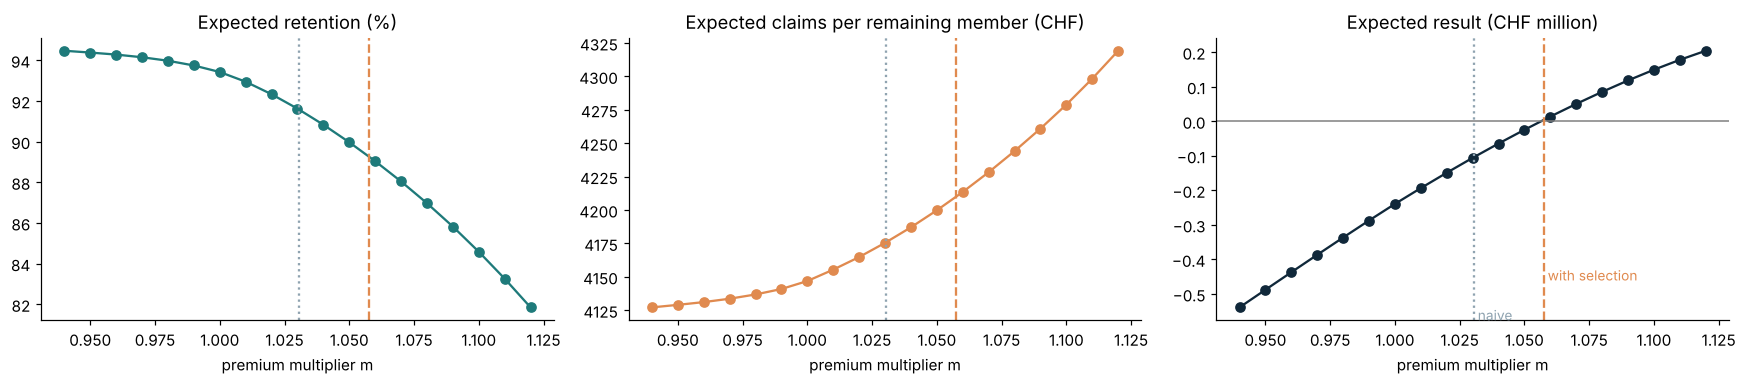

,retention,income_CHFm,cost_CHFm,result_CHFm,claims_per_member
m,,,,,
1.00,0.934,5.428,5.667,-0.239,4146.864
1.03,0.916,5.490,5.596,-0.106,4175.436
1.05,0.900,5.503,5.528,-0.025,4199.798
1.07,0.880,5.496,5.446,0.050,4228.299
1.10,0.846,5.443,5.294,0.149,4278.910


In [11]:
grid = np.round(np.arange(0.94, 1.121, 0.01), 2)
S = pd.DataFrame([scenario(m) for m in grid]).set_index("m")
fig, ax = plt.subplots(1, 3, figsize=(16, 3.6))
(S.retention * 100).plot(ax=ax[0], marker="o", color="#1E7A7A", title="Expected retention (%)")
S.claims_per_member.plot(ax=ax[1], marker="o", color="#E08A4F", title="Expected claims per remaining member (CHF)")
S.result_CHFm.plot(ax=ax[2], marker="o", color="#10283A", title="Expected result (CHF million)"); ax[2].axhline(0, color="grey", lw=1)
for a_ in ax:
    a_.axvline(naive_m, ls=":", color="#8FA3B0"); a_.axvline(aware_m, ls="--", color="#E08A4F"); a_.set_xlabel("premium multiplier m")
ax[2].text(naive_m, ax[2].get_ylim()[0], " naive", color="#8FA3B0", fontsize=9); ax[2].text(aware_m, ax[2].get_ylim()[0] * .8, " with selection", color="#E08A4F", fontsize=9)
plt.tight_layout(); plt.show()
S.loc[[1.0, 1.03, 1.05, 1.07, 1.1]].round(3)

## 6 · Reading the decision

**1. The draft tariff is too low.** At $m = 1$, Arvena's expected result is negative: the premiums would not cover next year's claims, the risk-equalisation payment and administration.

**2. Ignoring who leaves underestimates the required increase.** The naive calculation assumes that the same customers stay whatever the price. The selection-aware calculation shows that each price step makes the cheapest customers leave first (middle panel: claims per remaining member *rise* with the price), so part of every increase is eaten by a costlier remaining book. The required multiplier is therefore clearly higher than the naive one. This is the classic **adverse-selection spiral** in insurance (Rothschild & Stiglitz, 1976); risk equalisation exists to dampen it, but does not remove it.

**3. Both models were needed.** The regression of P1 says *how much* each customer will cost; the classification of P2 says *who* will stay. Neither alone answers the question.

### 6.1 · How robust is the answer?
Two uncertainties matter most: the cost forecast (Practical 1 showed that a portfolio total can be off by a few percent) and the price sensitivity of customers.

In [12]:
rows = []
for cf in (0.96, 1.00, 1.04):
    rows.append(dict(scenario=f"claims forecast × {cf}", break_even_m=break_even(claims_factor=cf)))
for sens in (1.5, 2.0):
    rows.append(dict(scenario=f"customers {sens}× as price-sensitive", break_even_m=break_even(sensitivity=sens)))
rob = pd.DataFrame(rows).set_index("scenario")
rob["break_even_m"] = rob.break_even_m.map(lambda v: f"{v:.3f}" if v == v else "none up to 1.20")
rob

,break_even_m
scenario,
claims forecast × 0.96,1.012
claims forecast × 1.0,1.058
claims forecast × 1.04,1.110
customers 1.5× as price-sensitive,1.105
customers 2.0× as price-sensitive,none up to 1.20


* A 4% error in the claims forecast moves the required premium by **about 5 points** — more than one-for-one, because a higher premium also drives away more cheap customers. Forecast accuracy at **portfolio level** is what the money depends on, which is why Practical 1 checked calibration by group.
* With more mobile customers the break-even premium rises; with customers **twice** as price-sensitive, **no** premium up to +20% covers the costs: every increase drives away enough healthy customers to make the remaining book costlier again. This is the **death spiral** that regulators fear, and the reason why risk equalisation, mandatory insurance and switching deadlines exist.

### ✏️ Exercise 3 — the recommendation
Write a five-line recommendation to Arvena's board: the multiplier you propose, the expected retention, the risk you see, and what Arvena should monitor during the renewal. Support each statement with a number from this notebook.

In [13]:
# ✅ SOLUTION
best = scenario(aware_m)
print(f"Proposal: raise the draft 2027 tariff by {100 * (aware_m - 1):.1f}% (m = {aware_m:.3f}).")
print(f"Expected retention {best['retention']:.1%}; expected claims per remaining member CHF {best['claims_per_member']:,.0f}.")
print(f"Ignoring selection would suggest only {100 * (naive_m - 1):.1f}% and leave a deficit of CHF {-scenario(naive_m)['result_CHFm'] * 1e6:,.0f}.")
print("Main risk: the claims forecast (±4% moves the required increase by about ±5 points).")
print("Monitor: switching notices received by 30 November, by age group and by supplementary tie.")

Proposal: raise the draft 2027 tariff by 5.8% (m = 1.058).
Expected retention 89.3%; expected claims per remaining member CHF 4,210.
Ignoring selection would suggest only 3.0% and leave a deficit of CHF 103,953.
Main risk: the claims forecast (±4% moves the required increase by about ±5 points).
Monitor: switching notices received by 30 November, by age group and by supplementary tie.


### 6.2 · What this analysis leaves out
* **Newcomers.** A lower price would also attract new customers, who are on average healthy switchers from other insurers.
* **Competitors' reactions.** We held other insurers' prices fixed.
* **Regulation.** The Federal Office of Public Health approves the premium; Arvena must justify it with its cost forecast, and premiums that would build excessive reserves are not approved.
* **Risk equalisation per person.** We used Arvena's average payment; the real fund pays different amounts for different age groups and health indicators.

## 7 · Reflection questions
1. In Part A, the network did not beat logistic regression. Name two situations in which you would still choose the structured network for this task.
2. Explain to a non-specialist, in three sentences and without formulas, why raising the price makes the average remaining customer more expensive.
3. Which single number of Practical 1 had the largest influence on the decision, and how would you reduce its uncertainty?
4. The data say switchers are healthier. Is it fair that Arvena's loyal, older customers pay for this effect? Who else bears it?

## References
* Rothschild, M., & Stiglitz, J. (1976). Equilibrium in competitive insurance markets. *Quarterly Journal of Economics*, 90(4), 629–649.
* Sill, J. (1998). Monotonic networks. *NeurIPS*, 10.
* Train, K. (2009). *Discrete Choice Methods with Simulation* (2nd ed.). Cambridge University Press.
* Federal Office of Public Health (BAG/OFSP): premium approval and risk equalisation (KVG Art. 16–17a, 61; KVAG Art. 16).